# Adding new layers to YOLO with PyTorch

### Key words

| Word | Meaning | Example |
|---|---|---|
| PyTorch (`torch`) | The library used to build and train neural networks | `import torch` |
| Tensor | A table of numbers with any number of dimensions | Shape `(3, 64, 64)` = one colour image |
| Layer | One step of calculation: numbers in, numbers out | `nn.Linear(4, 2)`: 4 numbers in, 2 out |
| Channel | One "layer" of an image or of features | An RGB image has 3 channels |
| Feature | A number that describes part of an image | "edge here", "round shape here" |
| Backbone | The first part of the model. It turns an image into features | YOLO layers 0 to 10 |
| Head | The last part. It turns features into the answer | Boxes, or a digit |
| Freeze | Stop a layer from changing during training | Keeps what YOLO already learned |
| Loss | A number that measures how wrong the model is. Training lowers it | `loss 0.23` |
| Optimizer (Adam) | The method that changes the values to lower the loss | `torch.optim.Adam(...)` |
| Learning rate | How big each change is | `lr=0.01` |
| Epoch | One pass over all training images | 5 epochs = every image seen 5 times |
| Accuracy | Share of correct answers on new images | 95% = 95 of 100 correct |
| Validation set | Images kept aside to watch the training | 200 images, never trained on |
| Overfitting | The model memorises the training images and is worse on new ones | Training loss 0.000, but mistakes on new images |
| Early stopping | Stop training when the validation accuracy no longer improves | Stopped at epoch 40 of 200 |
| Regularization (weight decay) | Keeps the trained values small, so the model memorises less | `weight_decay=0.01` |
| Residual connection | Output = input + a learned correction | `x + self.conv(x)` |
| `state_dict` | The learned values of a model, without code | `torch.save(model.state_dict(), ...)` |
| scikit-learn / scikit-image | Libraries that provide the digits dataset and sample photos | `load_digits()`, `ski.data.cat()` |

## 0. Setup
Run this cell once. Expected output: `True`.

In [36]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import skimage as ski
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from ultralytics import YOLO

Using this folder's uv environment: True


## 1. The data
The digits dataset from scikit-learn: 1,797 images of 8 × 8 pixels, each showing a digit from 0 to 9.

1797 images of (8, 8) pixels


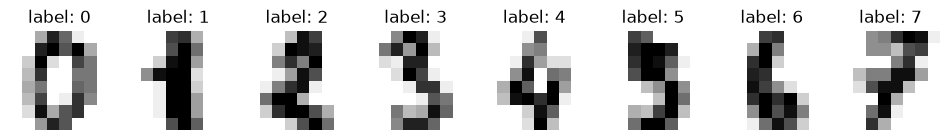

In [37]:
digits = load_digits()
print(len(digits.images), "images of", digits.images[0].shape, "pixels")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"label: {label}")
    ax.axis("off")
plt.show()

YOLO expects colour images (3 channels) with a size divisible by 32.
Each digit is converted from `(8, 8)` to `(3, 64, 64)`. Then the images are split into three groups:

| Group | Images | Used for |
|---|---|---|
| Training | 1,100 | Learning |
| Validation | 200 | Watching the training, to decide when to stop |
| Test | 497 | The final score, measured once at the end |

In [ ]:
x = torch.tensor(digits.images, dtype=torch.float32) / 16  # pixel values 0..16 -> 0..1
x = x.unsqueeze(1).repeat(1, 3, 1, 1)                       # 1 channel -> 3 channels
x = F.interpolate(x, size=64)                               # 8 x 8 -> 64 x 64 pixels
y = torch.tensor(digits.target)

torch.manual_seed(0)                                        # the same split on every run
order = torch.randperm(len(x))                              # shuffle, then split
x_train, y_train = x[order[:1100]], y[order[:1100]]
x_val, y_val = x[order[1100:1300]], y[order[1100:1300]]
x_test, y_test = x[order[1300:]], y[order[1300:]]
print("Training:", len(x_train), "| Validation:", len(x_val), "| Test:", len(x_test))

## 2. PyTorch basics: a layer and a model
A **layer** takes numbers in and gives numbers out. A **model** is a chain of layers.

In [39]:
layer = nn.Linear(4, 2)  # 4 numbers in, 2 numbers out
print("Layer output:", layer(torch.tensor([1.0, 2.0, 3.0, 4.0])))

tiny_model = nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 2))
print(tiny_model)

Layer output: tensor([ 0.8404, -0.3026], grad_fn=<ViewBackward0>)
Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)


## 3. Inside YOLO: backbone and head
YOLO is also a chain of layers. Layers 0 to 10 are the **backbone**. The layers after 10 form the detection **head**.

In [40]:
yolo = YOLO("yolo26n.pt")
for i, layer in enumerate(yolo.model.model):
    print(i, type(layer).__name__)

0 Conv
1 Conv
2 C3k2
3 Conv
4 C3k2
5 Conv
6 C3k2
7 Conv
8 C3k2
9 SPPF
10 C2PSA
11 Upsample
12 Concat
13 C3k2
14 Upsample
15 Concat
16 C3k2
17 Conv
18 Concat
19 C3k2
20 Conv
21 Concat
22 C3k2
23 Detect


The backbone turns an image into features. At each step the image becomes **smaller** and the number of **channels** grows.
Shape = (images, channels, height, width).

In [41]:
backbone = YOLO("yolo26n.pt").model.model[:11]  # layers 0 to 10

x_demo = torch.zeros(1, 3, 64, 64)  # one empty 64 x 64 image
with torch.no_grad():
    for i, layer in enumerate(backbone):
        x_demo = layer(x_demo)
        print(f"after layer {i:2} ({type(layer).__name__}): {tuple(x_demo.shape)}")

after layer  0 (Conv): (1, 16, 32, 32)
after layer  1 (Conv): (1, 32, 16, 16)
after layer  2 (C3k2): (1, 64, 16, 16)
after layer  3 (Conv): (1, 64, 8, 8)
after layer  4 (C3k2): (1, 128, 8, 8)
after layer  5 (Conv): (1, 128, 4, 4)
after layer  6 (C3k2): (1, 128, 4, 4)
after layer  7 (Conv): (1, 256, 2, 2)
after layer  8 (C3k2): (1, 256, 2, 2)
after layer  9 (SPPF): (1, 256, 2, 2)
after layer 10 (C2PSA): (1, 256, 2, 2)


**What to observe:** after layer 6 there are **128** channels, and after layer 10 there are **256** channels of 2 × 2.
These two numbers are used below.

## 4. The original head: object detection
With its original head, YOLO finds objects in photos. Example: sample photos from scikit-image.

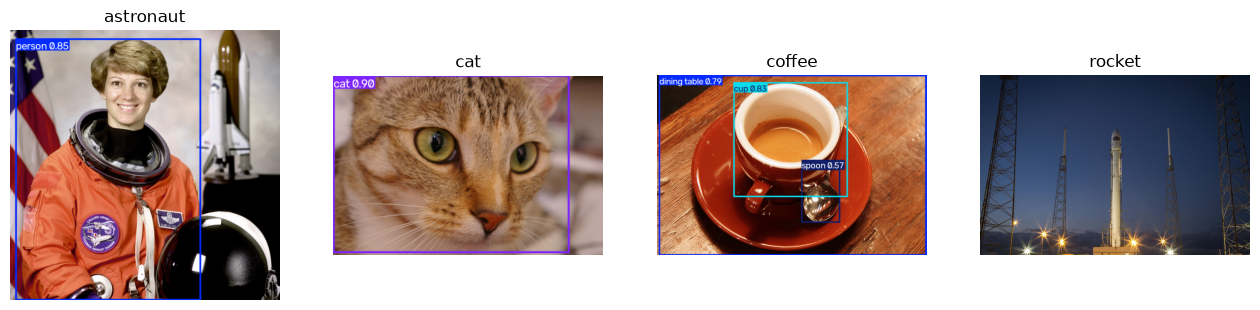

In [42]:
photos = {"astronaut": ski.data.astronaut(), "cat": ski.data.cat(), "coffee": ski.data.coffee(), "rocket": ski.data.rocket()}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, photo) in zip(axes, photos.items()):
    photo = cv2.cvtColor(photo, cv2.COLOR_RGB2BGR)  # scikit-image gives RGB colours, YOLO expects BGR
    r = yolo(photo, verbose=False)[0]
    ax.imshow(r.plot()[:, :, ::-1])  # BGR to RGB colours
    ax.set_title(name)
    ax.axis("off")
plt.show()

**What to observe:** the rocket has no box, because "rocket" is not in YOLO's list of 80 objects.

## 5. A new last layer: image classification

The detection head is replaced by a new head with 3 simple layers:
1. `AdaptiveAvgPool2d(1)`: averages each of the 256 channels into one number
2. `Flatten()`: turns the result into a list of 256 numbers
3. `Linear(256, 10)`: gives one score per digit (0 to 9)

The backbone is **frozen**, so only the new layers learn.
`extra_layer` adds a new middle layer, explained in section 7.

In [43]:
class ExtraLayer(nn.Module):
    """A new middle layer. It starts as 'do nothing' (all zeros) and learns a small correction."""

    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        nn.init.zeros_(self.conv.weight)
        nn.init.zeros_(self.conv.bias)

    def forward(self, x):
        return x + self.conv(x)  # input + learned correction


def build_model(extra_layer=False):
    layers = list(YOLO("yolo26n.pt").model.model[:11])  # a fresh copy of YOLO layers 0 to 10
    for layer in layers:
        layer.requires_grad_(False)                       # freeze: keep what YOLO learned
    if extra_layer:
        layers.insert(7, ExtraLayer(128))                 # new layer between YOLO layers 6 and 7
    head = [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10)]  # new last layers
    return nn.Sequential(*layers, *head)


def trainable(model):
    """Number of values that training can change."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model_a = build_model()
print("Values to train:", trainable(model_a))

Values to train: 2570


**What to observe:** only 2,570 values are trained (256 × 10 + 10), instead of the millions in YOLO.

## 6. Training the new layer

Each training step:
1. The model guesses the digits of 64 images.
2. The **loss** measures how wrong the guesses are.
3. `backward()` finds how each trainable value should change.
4. The optimizer changes the values a little.

`model.eval()` keeps the frozen YOLO layers exactly as they are. The new layers still learn.

**Two rules for proper training**
1. The **validation** images decide when to stop. The **test** images are never used during training.
2. **Early stopping:** training stops when the validation accuracy has not improved for 20 epochs (`patience=20`), and the best version of the model is kept. This avoids **overfitting**: memorising the training images instead of learning.
3. **Regularization** (`weight_decay=0.01`): at every step the trained values are pulled slightly towards zero. Smaller values make the model simpler, so it memorises less.

**How to read the output**

| Accuracy | Measured on | Meaning |
|---|---|---|
| train | Images used for learning | How well the model learned them |
| validation | Images kept aside | How well it does on new images, during training |
| test | Images never used | The final, honest score |

Example: train 100% and validation 90% means overfitting. The closer the two curves, the better.

In [ ]:
import copy


def accuracy(model, x=x_test, y=y_test):
    with torch.no_grad():
        return (model(x).argmax(1) == y).float().mean().item()


def train(model, max_epochs=200, patience=20, weight_decay=0.01):
    model.eval()
    values = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(values, lr=0.01, weight_decay=weight_decay)  # weight decay = regularization
    history = {"train": [], "validation": []}
    best_accuracy, best_values, waited = 0, None, 0

    for epoch in range(max_epochs):
        order = torch.randperm(len(x_train))  # a new order of the images in every epoch
        for i in range(0, len(x_train), 64):  # batches of 64 images
            batch = order[i:i + 64]
            loss = F.cross_entropy(model(x_train[batch]), y_train[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_accuracy = accuracy(model, x_train, y_train)
        validation_accuracy = accuracy(model, x_val, y_val)
        history["train"].append(train_accuracy)
        history["validation"].append(validation_accuracy)
        print(f"epoch {epoch + 1}: loss {loss.item():.3f} | train {train_accuracy:.1%} | validation {validation_accuracy:.1%}")

        if validation_accuracy > best_accuracy:  # better than before: remember this version
            best_accuracy, best_values, waited = validation_accuracy, copy.deepcopy(model.state_dict()), 0
        else:
            waited += 1
            if waited == patience:  # no improvement for `patience` epochs: stop
                print(f"Stopped early at epoch {epoch + 1}.")
                break

    model.load_state_dict(best_values)  # go back to the best version

    pd.DataFrame(history).plot(figsize=(8, 3), xlabel="epoch", ylabel="accuracy", title="Accuracy during training")
    plt.show()
    print(f"Best version | train {accuracy(model, x_train, y_train):.1%} | validation {best_accuracy:.1%} | test {accuracy(model):.1%}")


train(model_a)

**What to observe:** the loss goes down and the validation accuracy goes up, then training stops by itself. YOLO was never trained on digits, so its frozen features give only a partial result. Section 7 improves it.

## 7. A new middle layer

`ExtraLayer` (defined in section 5) is placed **between YOLO layers 6 and 7**. It has 128 channels, like layer 6.

- It starts with all values at zero, so at first it changes nothing: output = input + 0.
  This protects the frozen YOLO layers after it.
- Training then learns a small correction that helps the new task.

This idea, output = input + correction, is called a **residual connection**.

In [ ]:
torch.manual_seed(0)
model_b = build_model(extra_layer=True)
print("Values to train:", trainable(model_b))
train(model_b)

## 8. Comparison and predictions

In [ ]:
def scores(model):
    return {
        "values trained": trainable(model),
        "train": f"{accuracy(model, x_train, y_train):.1%}",
        "validation": f"{accuracy(model, x_val, y_val):.1%}",
        "test": f"{accuracy(model):.1%}",
    }


pd.DataFrame({"new last layer only": scores(model_a), "+ new middle layer": scores(model_b)}).T

In [ ]:
with torch.no_grad():
    predicted = model_b(x_test[:8]).argmax(1)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, image, true, guess in zip(axes, x_test[:8], y_test[:8], predicted):
    ax.imshow(image[0], cmap="gray_r")
    ax.set_title(f"true {true}\nguess {guess}")
    ax.axis("off")
plt.show()

**What to observe:** the middle layer trains more values. It usually raises the accuracy, but not always:
more values also need more data and more epochs.

**Experiment:** change `weight_decay=0.01` to `0` (no regularization) or `0.1` in `train`, or move the middle layer to another position
(the channel number must match the table in section 3).

## 9. Saving the new model

`state_dict()` holds only the learned values (no code), which is the safest way to store PyTorch weights.
To use the model again, build the same structure and load the values into it.

In [ ]:
torch.save(model_b.state_dict(), "outputs/digit_classifier.pt")

loaded = build_model(extra_layer=True)
loaded.load_state_dict(torch.load("outputs/digit_classifier.pt", weights_only=True))
print("Loaded model, test accuracy:", f"{accuracy(loaded):.1%}")

## Summary

| Step | PyTorch code |
|---|---|
| Reuse YOLO's backbone | `YOLO("yolo26n.pt").model.model[:11]` |
| Freeze it | `layer.requires_grad_(False)` |
| New last layer | `nn.Linear(256, 10)` |
| New middle layer | `layers.insert(7, ExtraLayer(128))` |
| Train | loss → `backward()` → `optimizer.step()` |
| Save and load | `torch.save(model.state_dict(), ...)` and `load_state_dict(...)` |